""""""

In [1]:
!apt-get update -qq
!apt-get install -y openjdk-17-jdk-headless -qq

!pip install -q --force-reinstall pyspark==3.5.1

import os, subprocess, sys

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["PATH"] += ":/usr/lib/jvm/java-17-openjdk-amd64/bin"

from pyspark.sql import SparkSession

spark=(SparkSession.builder
         .master("local[*]")
         .appName("colab-spark")
         .getOrCreate())

spark.range(10).show()

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.1 which is incompatible.
+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
|  5|
|  6|
|  7|
|  8|
|  9|
+---+



In [2]:
!pip install pyspark

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pyspark.pandas as ps
from matplotlib.ticker import FuncFormatter

from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml import Pipeline

/usr/local/lib/python3.13/dist-packages/pyspark/pandas/__init__.py:50: UserWarning: 'PYARROW_IGNORE_TIMEZONE' environment variable was not set. It is required to set this environment variable to '1' in both driver and executor sides if you use pyarrow>=2.0.0. pandas-on-Spark will set it for you but it does not work if there is a Spark context already launched.
  warnings.warn(


# 1. Análisis Exploratorio de Datos

## El objetivo es averiguar según el índice de masa corporal, que categoría de personas ejerce mayor carga financiera a la aseguradora

## 1.1. Carga de datos

Carga del dataset e inspección de datos

In [4]:
df=ps.read_csv("insurance.csv")

/usr/local/lib/python3.13/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning: If `index_col` is not specified for `read_csv`, the default index is attached which can cause additional overhead.
  warnings.warn(message, PandasAPIOnSparkAdviceWarning)


In [5]:
df.head()


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [6]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4738.268200
50%,39.000000,30.400000,1.000000,9377.904700
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
df.info()

<class 'pyspark.pandas.frame.DataFrame'>
Int64Index: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int32  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int32  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int32(2), object(3)

## 1.2. Limpieza de datos

Se comprueba si existen valores nulos, en este caso no hay

In [8]:
df.isnull().sum(axis=0)

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Para la pregunta de negocio, se crea una columna que categoriza el bmi en 4 casos:

- Bajo_peso: menor o igual a 18.5

- Peso_normal: menor o igual a 24.9

- Sobrepeso: menor o igual a 29.9

- Obesidad: mayor a 29.9

In [9]:
def categorizar_imc(bmi):

    if bmi is None:

        return None

    elif bmi<=18.5:

        return "Bajo_peso"

    elif bmi<=24.9:

        return "Peso_normal"

    elif bmi<=29.9:

        return "Sobrepeso"

    else:

        return "Obesidad"

df["bmi_category"]=df["bmi"].apply(categorizar_imc)

In [10]:
df[["bmi", "bmi_category"]].head()

,bmi,bmi_category
0,27.900,Sobrepeso
1,33.770,Obesidad
2,33.000,Obesidad
3,22.705,Peso_normal
4,28.880,Sobrepeso


## 1.3. Análisis univariable y bivariable

### Distribución de cargos médicos

/usr/local/lib/python3.13/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning: `to_numpy` loads all data into the driver's memory. It should only be used if the resulting NumPy ndarray is expected to be small.
  warnings.warn(message, PandasAPIOnSparkAdviceWarning)


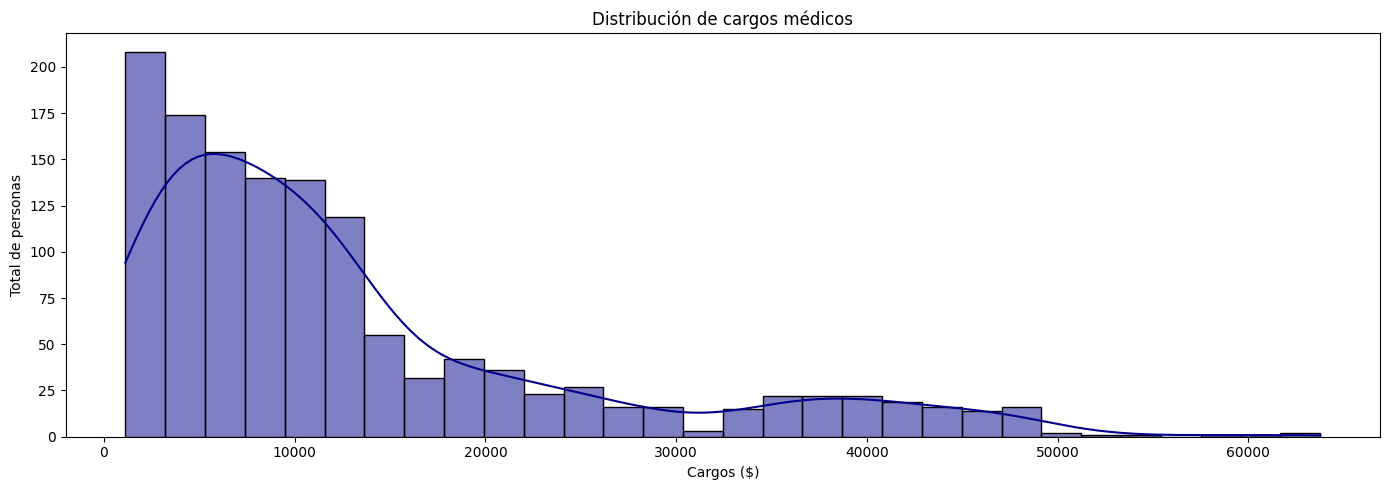

In [11]:
plt.figure(figsize=(14, 5))

sns.histplot(df["charges"].to_numpy(), kde=True, color="darkblue", bins=30)
plt.title("Distribución de cargos médicos")
plt.xlabel("Cargos ($)")
plt.ylabel("Total de personas")

plt.tight_layout()
plt.show()

La distribución está fuertemente sesgada a la derecha. Esto significa que la gran mayoría de los beneficiarios incurren en gastos relativamente bajos (por debajo de los 15,000 dólares). Sin embargo, la derecha representa a un grupo más pequeño de pacientes que generan gastos extremos (llegando incluso a más de 60,000 dólares)

### Distribución de índice de masa corporal

/usr/local/lib/python3.13/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning: `to_numpy` loads all data into the driver's memory. It should only be used if the resulting NumPy ndarray is expected to be small.
  warnings.warn(message, PandasAPIOnSparkAdviceWarning)


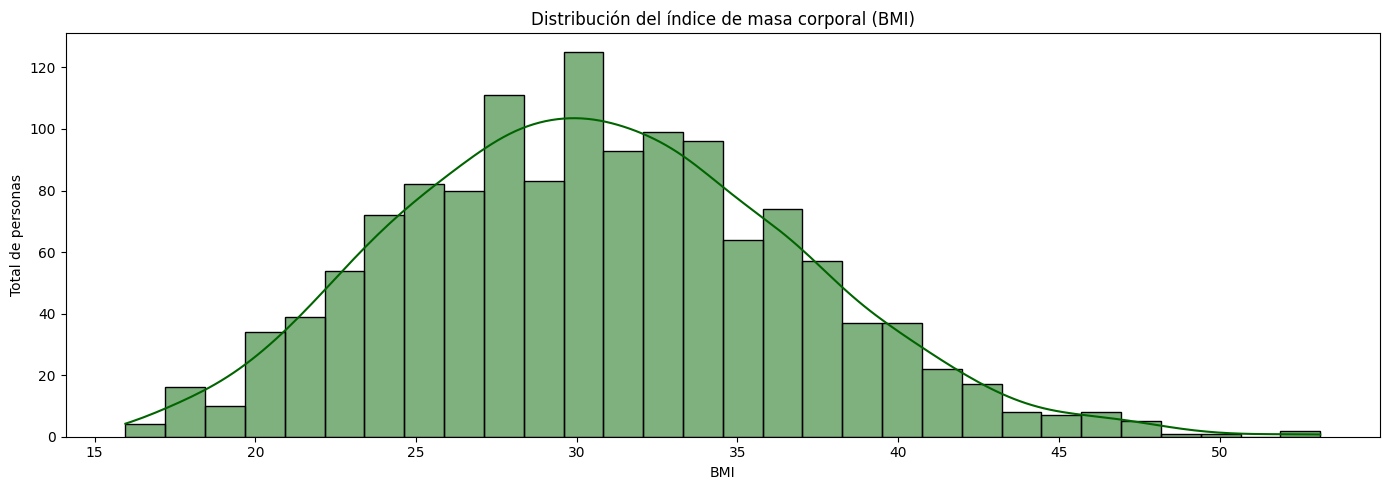

In [12]:
plt.figure(figsize=(14, 5))

sns.histplot(df["bmi"].to_numpy(), kde=True, color="darkgreen", bins=30)
plt.title("Distribución del índice de masa corporal (BMI)")
plt.xlabel("BMI")
plt.ylabel("Total de personas")

plt.tight_layout()
plt.show()

La distribución es casi normal. El promedio se sitúa alrededor de 30

### Proporción de fumadores

/usr/local/lib/python3.13/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning: `to_pandas` loads all data into the driver's memory. It should only be used if the resulting pandas DataFrame is expected to be small.
  warnings.warn(message, PandasAPIOnSparkAdviceWarning)


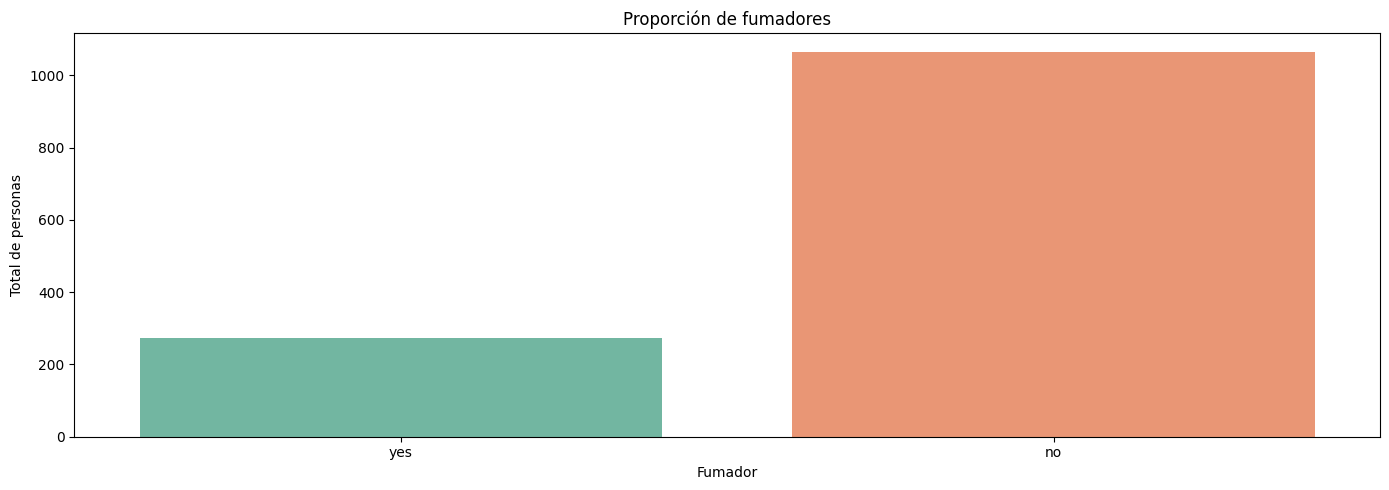

In [13]:
plt.figure(figsize=(14, 5))

sns.countplot(x="smoker", data=df.to_pandas(), hue="smoker", palette="Set2")
plt.title("Proporción de fumadores")
plt.xlabel("Fumador")
plt.ylabel("Total de personas")

plt.tight_layout()
plt.show()

Una mayoría de los beneficiarios de la aseguradora no fuman. Los fumadores representan aproximadamente una quinta parte del total

### Distribución por categoría de índice de masa corporal

/usr/local/lib/python3.13/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning: `to_pandas` loads all data into the driver's memory. It should only be used if the resulting pandas DataFrame is expected to be small.
  warnings.warn(message, PandasAPIOnSparkAdviceWarning)


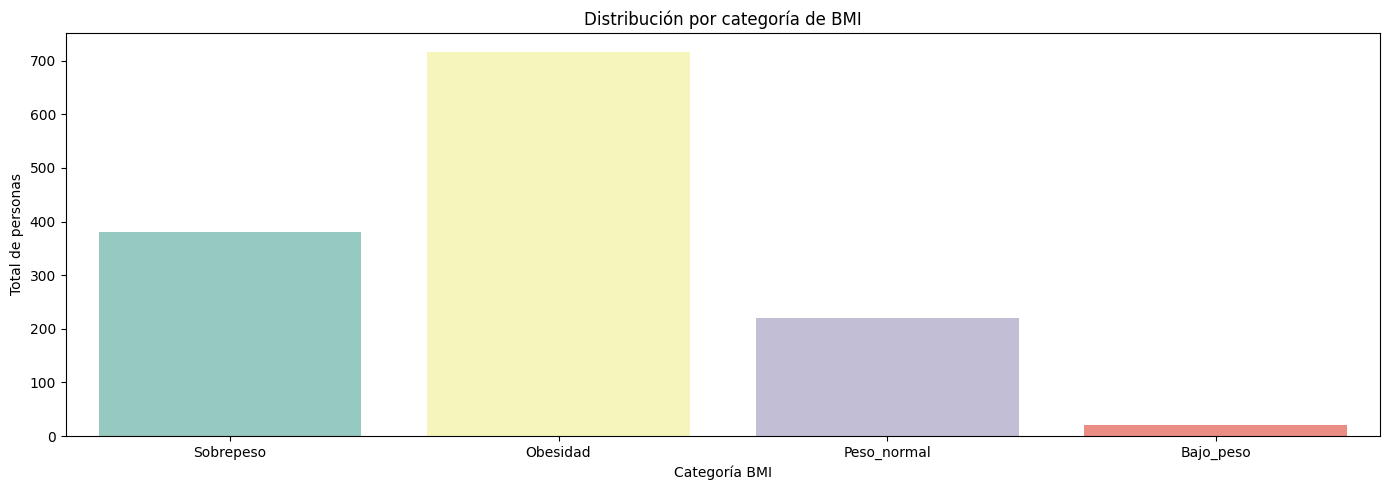

In [14]:
plt.figure(figsize=(14, 5))

sns.countplot(x="bmi_category", data=df.to_pandas(), hue="bmi_category", palette="Set3")
plt.title("Distribución por categoría de BMI")
plt.xlabel("Categoría BMI")
plt.ylabel("Total de personas")

plt.tight_layout()
plt.show()

Más de la mitad de la población del seguro tiene obesidad, seguida de aquellos con sobrepeso. Las personas con bajo peso representan una fracción minúscula

### Cargos médicos por tipo de fumador

/usr/local/lib/python3.13/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning: `to_pandas` loads all data into the driver's memory. It should only be used if the resulting pandas DataFrame is expected to be small.
  warnings.warn(message, PandasAPIOnSparkAdviceWarning)


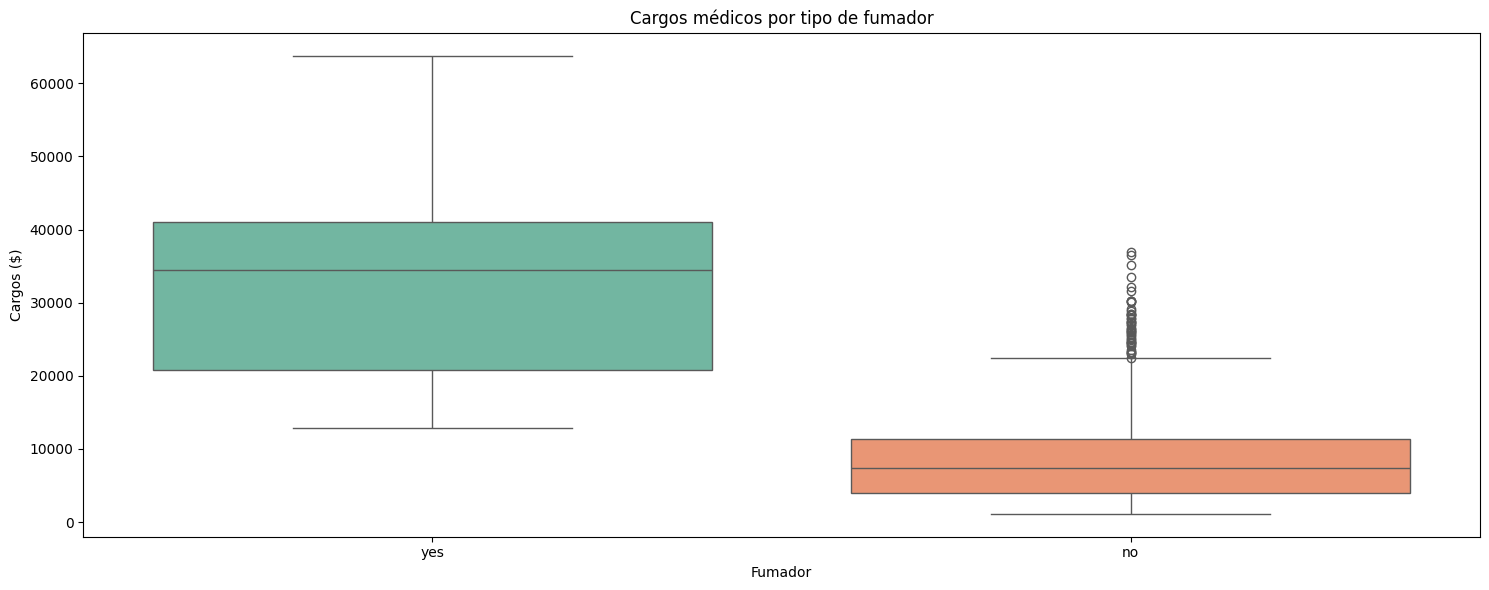

In [15]:
plt.figure(figsize=(15, 6))

sns.boxplot(x="smoker", y="charges", data=df.to_pandas(), hue="smoker", palette="Set2")
plt.title("Cargos médicos por tipo de fumador")
plt.xlabel("Fumador")
plt.ylabel("Cargos ($)")

plt.tight_layout()
plt.show()

El costo mínimo que le factura un fumador a la aseguradora es más alto que el costo promedio de un no fumador. El tabaquismo eleva radicalmente los gastos médicos

### Relación de índice de masa corporal y cargos médicos por fumador

/usr/local/lib/python3.13/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning: `to_pandas` loads all data into the driver's memory. It should only be used if the resulting pandas DataFrame is expected to be small.
  warnings.warn(message, PandasAPIOnSparkAdviceWarning)


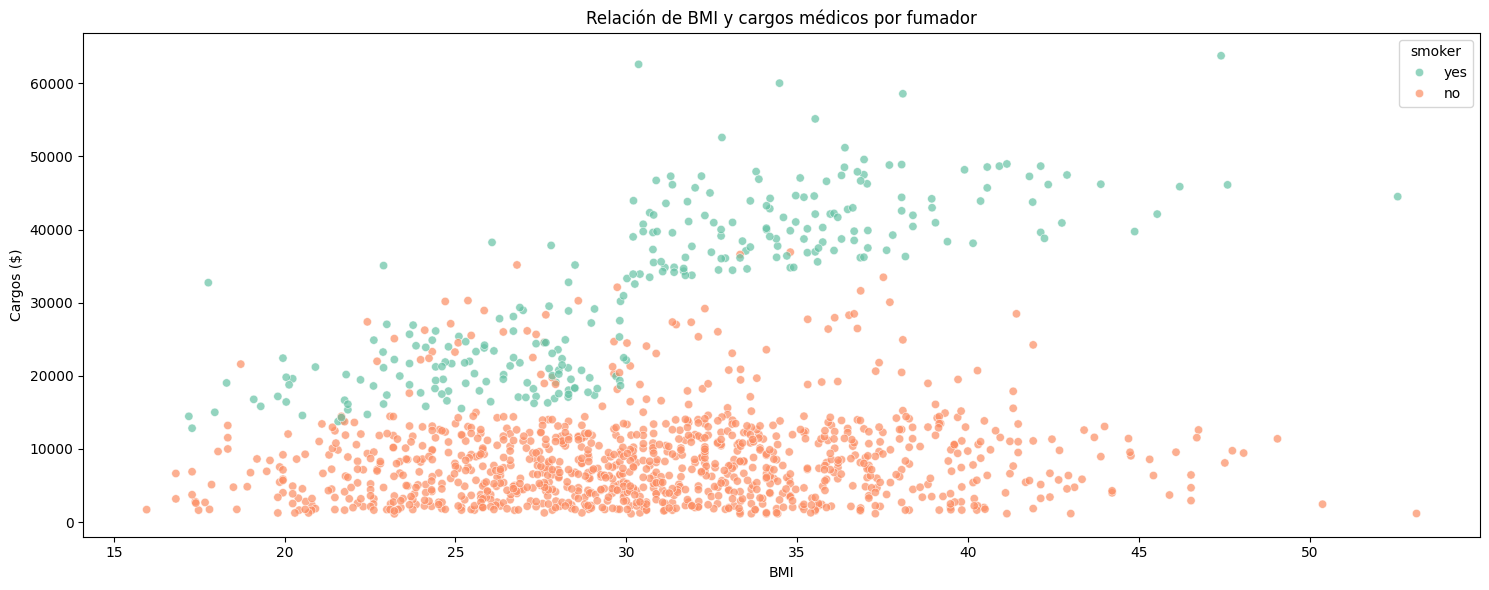

In [16]:
plt.figure(figsize=(15, 6))

sns.scatterplot(x="bmi", y="charges", data=df.to_pandas(), hue="smoker", palette="Set2", alpha=0.7)
plt.title("Relación de BMI y cargos médicos por fumador")
plt.xlabel("BMI")
plt.ylabel("Cargos ($)")

plt.tight_layout()
plt.show()

- Los no fumadores tienen costos bajos y estables en su mayoría, independientemente de si su BMI sube.

- Los fumadores presentan costos sistemáticamente altos.

- En la nube de puntos verdes que se dispara por encima de los 30000 dólares, todos ellos se encuentran exactamente donde el eje de BMI cruza la marca de 30, esto quiere decir que la relación de ser fumador y tener obesidad aumenta considerablemente su gasto médico

## 1.4. Idenficiación de outliers

/usr/local/lib/python3.13/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning: `to_pandas` loads all data into the driver's memory. It should only be used if the resulting pandas Series is expected to be small.
  warnings.warn(message, PandasAPIOnSparkAdviceWarning)
/usr/local/lib/python3.13/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning: `to_pandas` loads all data into the driver's memory. It should only be used if the resulting pandas Series is expected to be small.
  warnings.warn(message, PandasAPIOnSparkAdviceWarning)


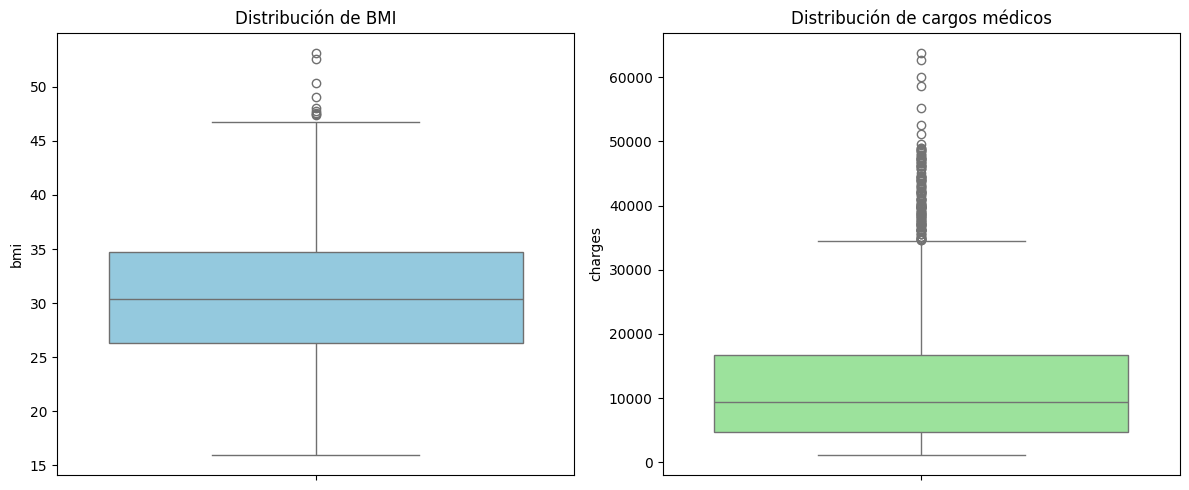

In [17]:
def identificar_outliers(data):

    Q1=data.quantile(0.25)
    Q3=data.quantile(0.75)
    IQR=Q3-Q1
    cota_menor=Q1-1.5*IQR
    cota_superior=Q3+1.5*IQR

    return (data<cota_menor) | (data>cota_superior)

outliers_bmi=df[identificar_outliers(df["bmi"])]
outliers_charges=df[identificar_outliers(df["charges"])]

fig, axes=plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["bmi"].to_pandas(), ax=axes[0], color="skyblue")
axes[0].set_title("Distribución de BMI")

sns.boxplot(y=df["charges"].to_pandas(), ax=axes[1], color="lightgreen")
axes[1].set_title("Distribución de cargos médicos")

plt.tight_layout()
plt.show()

- En el BMI se identificaron pocos valores atípicos. Estos corresponden a asegurados con un BMI superior a 45, lo cual entra en la categoría de obesidad extrema u obesidad mórbida.

- En cargos médicos se identificaron muchos valores atípicos, que superan los 30000 dólares. La mayoría de los siniestros son de bajo costo, pero hay un pequeño porcentaje de pacientes que generan facturas extraordinariamente altas.

### Según el BMI, ¿qué grupo representa la mayor carga financiera para la aseguradora?

/usr/local/lib/python3.13/dist-packages/pyspark/pandas/groupby.py:893: FutureWarning: Default value of `numeric_only` will be changed to `False` instead of `True` in 4.0.0.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning: `to_pandas` loads all data into the driver's memory. It should only be used if the resulting pandas DataFrame is expected to be small.
  warnings.warn(message, PandasAPIOnSparkAdviceWarning)


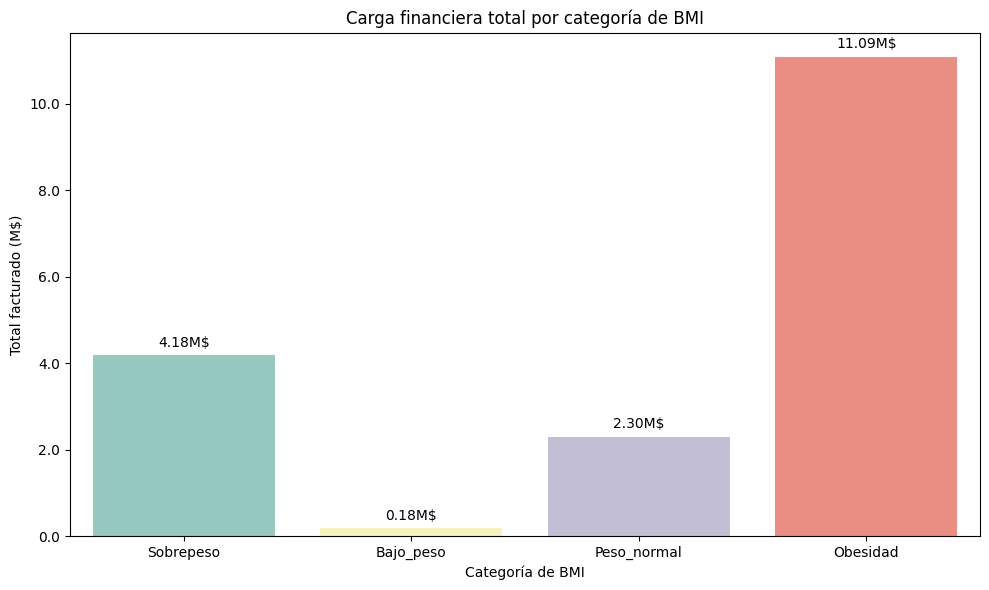

In [18]:
carga_financiera=df.groupby("bmi_category")["charges"].sum().reset_index().to_pandas()

plt.figure(figsize=(10, 6))

grafico=sns.barplot(x="bmi_category", y="charges", data=carga_financiera, hue="bmi_category", palette="Set3")

plt.title("Carga financiera total por categoría de BMI")
plt.xlabel("Categoría de BMI")
plt.ylabel("Total facturado (M$)")

def formatear_millones(x, pos):

    return f"{x/1e6:.1f}"

plt.gca().yaxis.set_major_formatter(FuncFormatter(formatear_millones))

for p in grafico.patches:

    valor=p.get_height()

    grafico.annotate(f"{valor/1e6:.2f}M$",
                      (p.get_x()+p.get_width()/2., p.get_height()),
                      ha="center", va="center",
                      xytext=(0, 9),
                      textcoords="offset points")

plt.tight_layout()
plt.show()

- El grupo de pacientes con obesidad representa la mayor carga financiera.

- Existe una escalada directa en los costos totales a medida que aumenta el peso de los asegurados, el grupo de "Sobrepeso" ($4.18M) casi duplica el costo acumulado del grupo de "Peso normal".

La magnitud del impacto: El costo de las personas con obesidad no solo es el más alto, sino que supera ampliamente a la suma de los otros tres grupos combinados (que totalizan aproximadamente $6.66 millones).

## 1.5. Conclusión

- Los cargos médicos son mayoritariamente moderados, aunque existen casos aislados con costes muy elevados. En cuanto a la población, predominan las personas con sobrepeso y obesidad.

- Fumar es la variable que más encarece los gastos médicos, mostrando una fuerte relación directa con el aumento de los costes.

- El índice de masa corporal (BMI) también incrementa los gastos de forma moderada, pero su efecto se dispara cuando se combina con el hábito de fumar.

- Las categorías en BMI de obesidad y sobrepeso generan la mayor carga financiera total para la aseguradora, por el alto volumen de pacientes y sus mayores costes individuales.

- El BMI es un factor clave para entender los gastos sanitarios, pero para predecir el coste real de un asegurado de forma precisa, debe analizarse siempre en conjunto con el tabaquismo.

# 2. Modelo de Regresión Lineal

El objetivo es utilizar un modelo de Regresión Lineal para predecir la variable "charges"

## 2.1. Transformación de variables

Se definen y separan las columnas categóricas y numéricas

In [19]:
columna_categoria=["sex", "smoker", "region"]
columna_numerica=["age", "bmi", "children"]

- StringIndexer convierte los strings a índices numéricos
- OneHotEncoder convierte los índices en vectores binarios

In [20]:
indexers=[
    StringIndexer(inputCol=c, outputCol=f"{c}_indexed", handleInvalid="keep")
    for c in columna_categoria
]

encoders=[
    OneHotEncoder(inputCol=f"{c}_indexed", outputCol=f"{c}_encoded")
    for c in columna_categoria
]

- VectorAssembler unifica todas las características en una sola columna vector


In [21]:
assembler_inputs=[f"{c}_encoded" for c in columna_categoria]+columna_numerica
assembler=VectorAssembler(inputCols=assembler_inputs, outputCol="raw_features")

- StandardScaler estandariza las características para que tengan media 0 y varianza 1

In [22]:
scaler=StandardScaler(inputCol="raw_features", outputCol="features", withStd=True, withMean=True)

## 2.2. Definición del modelo de Regresión Lineal

In [23]:
regresion_lineal=LinearRegression(featuresCol="features", labelCol="charges")

 Se construye el pipeline y este ejecuta todos los pasos en el orden correcto

In [24]:
pasos=indexers+encoders+[assembler, scaler, regresion_lineal]
pipeline=Pipeline(stages=pasos)

Se dividen los datos para el entrenamiento (80%) y prueba (20%)

In [25]:
dato_entrenamiento, dato_prueba=df.to_spark().randomSplit([0.8, 0.2], seed=42)

/usr/local/lib/python3.13/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning: If `index_col` is not specified for `to_spark`, the existing index is lost when converting to Spark DataFrame.
  warnings.warn(message, PandasAPIOnSparkAdviceWarning)


Se entrena el modelo

In [26]:
modelo=pipeline.fit(dato_entrenamiento)

## 2.3. Prueba del modelo de Regresión Lineal

Se realizan predicciones con el modelo y se evalúan

In [27]:
predicciones=modelo.transform(dato_prueba)

In [28]:
evaluador_rmse=RegressionEvaluator(predictionCol="prediction", labelCol="charges", metricName="rmse")
evaluador_r2=RegressionEvaluator(predictionCol="prediction", labelCol="charges", metricName="r2")

rmse=evaluador_rmse.evaluate(predicciones)
r2=evaluador_r2.evaluate(predicciones)

print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse}")
print(f"R-cuadrado (R2): {r2}")

predicciones.select("features", "charges", "prediction").show(5)

Raíz del Error Cuadrático Medio (RMSE): 5660.5582503423375
R-cuadrado (R2): 0.7955176463467358
+--------------------+-----------+------------------+
|            features|    charges|        prediction|
+--------------------+-----------+------------------+
|[0.99594664582015...|  2201.0971|308.07857869087456|
|[0.99594664582015...| 18223.4512|26033.038938857073|
|[0.99594664582015...|7323.734819| 2741.400457692096|
|[0.99594664582015...|  1622.1885| 2385.828110670993|
|[0.99594664582015...| 2211.13075|5058.6357860562575|
+--------------------+-----------+------------------+
only showing top 5 rows

